**Live deployment link:** https://PASTE-YOUR-LIVE-LINK-HERE

**Name:** Hamza Afzal | **Roll No:** SP24-BSE-035 | **Course:** Machine Learning Fundamentals (AIC354) | **Assignment 2, Task 2**

# Heart Disease Prediction System

## Introduction
**Definition:** This is a binary classification task. It predicts whether a patient has heart disease (Yes) or not (No).

**Application:** Doctors could use a tool like this to get a quick first signal. It is only a learning project and not a medical tool.

**Dataset:** Heart Disease dataset from the UCI Machine Learning Repository (Cleveland data, 303 patients, 14 attributes). Link: https://archive.ics.uci.edu/dataset/45/heart+disease

## Input and Output
The original dataset has 13 input attributes. The assignment says to use only 4. I chose four categorical attributes. Each one has a few clear values, so the Titanic label-encoding steps can be reused directly.

| Input attribute | Meaning | Possible values |
|---|---|---|
| **ChestPain** | Type of chest pain | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **ExerciseAngina** | Chest pain caused by exercise | No, Yes |
| **STSlope** | Slope of the ST segment at peak exercise | Upsloping, Flat, Downsloping |
| **Thal** | Thalassemia blood test result | Normal, Fixed Defect, Reversable Defect |

| Output attribute | Possible values |
|---|---|
| **HeartDisease** | Yes, No |

### Why these 4 attributes?
I compared different 4-attribute combinations of the categorical columns with 5-fold cross validation (see Step 4). This combination gave the best score (about 80%). All four are also easy for a user to pick from a drop-down list.

## Table of Contents
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction (choosing 4 attributes)
- Step 5: Label Encoding
- Step 6: Training Phase
- Step 7: Testing Phase
- Step 8: Application Phase
- Step 9: Feedback Phase
- Step 10: Deployment
- Conclusion

## Code

### Step 1: Import Libraries

In [1]:
# numpy and pandas for arrays and tables
import numpy as np
import pandas as pd

# pickle to save and load the trained model
import pickle

# split data, compare feature sets
from sklearn.model_selection import train_test_split, cross_val_score

# convert text categories into numbers
from sklearn.preprocessing import LabelEncoder

# the Support Vector Classifier
from sklearn import svm

# evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# nice table for the final prediction
from prettytable import PrettyTable

# plots
import matplotlib.pyplot as plt
import seaborn as sns

import itertools

### Step 2: Load Sample Data

The UCI file has 14 attributes. `heart-disease-cleveland-full.csv` is the full original data. `heart-sample-data.csv` is the same data with only my 4 chosen inputs and the output. Categories are written as words (like in the Titanic data) so they are easy to read.

In [2]:
# full original dataset (all 14 attributes), only used to see what it looks like
full_data = pd.read_csv("heart-disease-cleveland-full.csv")
print("Full UCI Cleveland data shape:", full_data.shape)
print(list(full_data.columns))

# the sample data used in this project: 4 inputs + 1 output
sample_data = pd.read_csv("heart-sample-data.csv")
pd.set_option("display.max_rows", 20, "display.max_columns", None)
print("\n\nSample Data:")
print("============\n")
print(sample_data)

Full UCI Cleveland data shape: (303, 14)
['age', 'gender', 'chest pain', 'rest SBP', 'cholesterol', 'fasting blood sugar > 120', 'rest ECG', 'max HR', 'exerc ind ang', 'ST by exercise', 'slope peak exc ST', 'major vessels colored', 'thal', 'diameter narrowing']


Sample Data:

            ChestPain ExerciseAngina      STSlope               Thal  \
0      Typical Angina             No  Downsloping       Fixed Defect   
1        Asymptomatic            Yes         Flat             Normal   
2        Asymptomatic            Yes         Flat  Reversable Defect   
3    Non-Anginal Pain             No  Downsloping             Normal   
4     Atypical Angina             No    Upsloping             Normal   
..                ...            ...          ...                ...   
298    Typical Angina             No         Flat  Reversable Defect   
299      Asymptomatic             No         Flat  Reversable Defect   
300      Asymptomatic            Yes         Flat  Reversable Defect   
30

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
print("Attributes in Sample Data:")
print(sample_data.columns)

print("\nNumber of Instances in Sample Data:", sample_data["ChestPain"].count())

print("\nValue counts for each attribute:")
for col in sample_data.columns:
    print("\n", sample_data[col].value_counts().to_string())

Attributes in Sample Data:
Index(['ChestPain', 'ExerciseAngina', 'STSlope', 'Thal', 'HeartDisease'], dtype='object')

Number of Instances in Sample Data: 303

Value counts for each attribute:

 ChestPain
Asymptomatic        144
Non-Anginal Pain     86
Atypical Angina      50
Typical Angina       23

 ExerciseAngina
No     204
Yes     99

 STSlope
Upsloping      142
Flat           140
Downsloping     21

 Thal
Normal               166
Reversable Defect    117
Fixed Defect          18
?                      2

 HeartDisease
No     164
Yes    139


#### Step 3.2: Pre-process Sample Data
Unlike the Titanic data, this data is **not** fully clean. The `Thal` column has a few missing values written as `?`. A model cannot use `?` as a real category, so I remove those rows.

In [4]:
print("Rows before cleaning:", len(sample_data))
print("Missing values ('?') per column:")
print((sample_data == "?").sum())

# remove rows that contain a missing value
sample_data = sample_data[(sample_data != "?").all(axis=1)].reset_index(drop=True)

print("\nRows after cleaning:", len(sample_data))

Rows before cleaning: 303
Missing values ('?') per column:
ChestPain         0
ExerciseAngina    0
STSlope           0
Thal              2
HeartDisease      0
dtype: int64

Rows after cleaning: 301


### Step 4: Feature Extraction

The assignment asks for only 4 input attributes. The code below tests every 4-attribute combination of the categorical columns of the full data with 5-fold cross validation. This is only used to **choose** the attributes. The final model below uses the 4 columns in `sample_data`.

In [5]:
full_clean = full_data[(full_data != "?").all(axis=1)]
candidates = ["gender", "chest pain", "exerc ind ang", "slope peak exc ST",
              "thal", "rest ECG", "fasting blood sugar > 120"]
target = full_clean["diameter narrowing"]

scores = []
for combo in itertools.combinations(candidates, 4):
    X = full_clean[list(combo)].astype(str).apply(lambda col: LabelEncoder().fit_transform(col))
    score = cross_val_score(svm.SVC(gamma="auto"), X, target, cv=5).mean()
    scores.append((round(score, 3), combo))

print("Top 5 combinations of 4 attributes (5-fold CV accuracy):\n")
for score, combo in sorted(scores, reverse=True)[:5]:
    print(score, combo)

Top 5 combinations of 4 attributes (5-fold CV accuracy):

0.798 ('chest pain', 'exerc ind ang', 'slope peak exc ST', 'thal')
0.788 ('chest pain', 'exerc ind ang', 'thal', 'rest ECG')
0.781 ('chest pain', 'exerc ind ang', 'thal', 'fasting blood sugar > 120')
0.774 ('gender', 'chest pain', 'thal', 'rest ECG')
0.774 ('gender', 'chest pain', 'exerc ind ang', 'thal')


The best combination is `chest pain`, `exerc ind ang`, `slope peak exc ST` and `thal`. These are the four columns in my sample data.

### Step 5: Label Encoding (text is converted into numbers)

#### Step 5.1: Train the Label Encoder

In [6]:
# every possible value of each attribute
chestpain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
exerciseangina = pd.DataFrame({"ExerciseAngina": ["No", "Yes"]})
stslope = pd.DataFrame({"STSlope": ["Upsloping", "Flat", "Downsloping"]})
thal = pd.DataFrame({"Thal": ["Normal", "Fixed Defect", "Reversable Defect"]})
heartdisease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# one LabelEncoder per attribute
chestpain_label_encoder = LabelEncoder()
exerciseangina_label_encoder = LabelEncoder()
stslope_label_encoder = LabelEncoder()
thal_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()

# train (fit) the encoders
chestpain_label_encoder.fit(np.ravel(chestpain))
exerciseangina_label_encoder.fit(np.ravel(exerciseangina))
stslope_label_encoder.fit(np.ravel(stslope))
thal_label_encoder.fit(np.ravel(thal))
heartdisease_label_encoder.fit(np.ravel(heartdisease))

# show which number each value got
for name, enc in [("ChestPain", chestpain_label_encoder), ("ExerciseAngina", exerciseangina_label_encoder),
                  ("STSlope", stslope_label_encoder), ("Thal", thal_label_encoder),
                  ("HeartDisease", heartdisease_label_encoder)]:
    print(name, "->", dict(zip(enc.classes_, enc.transform(enc.classes_))))

ChestPain -> {'Asymptomatic': np.int64(0), 'Atypical Angina': np.int64(1), 'Non-Anginal Pain': np.int64(2), 'Typical Angina': np.int64(3)}
ExerciseAngina -> {'No': np.int64(0), 'Yes': np.int64(1)}
STSlope -> {'Downsloping': np.int64(0), 'Flat': np.int64(1), 'Upsloping': np.int64(2)}
Thal -> {'Fixed Defect': np.int64(0), 'Normal': np.int64(1), 'Reversable Defect': np.int64(2)}
HeartDisease -> {'No': np.int64(0), 'Yes': np.int64(1)}


#### Step 5.2: Label Encode the Output

In [7]:
sample_data_encoded_output = sample_data.copy()

sample_data["encoded_heartdisease"] = heartdisease_label_encoder.transform(sample_data["HeartDisease"])
print(sample_data[["HeartDisease", "encoded_heartdisease"]].head(10))

sample_data_encoded_output[["ChestPain", "ExerciseAngina", "STSlope", "Thal", "HeartDisease"]] = \
    sample_data[["ChestPain", "ExerciseAngina", "STSlope", "Thal", "encoded_heartdisease"]]

sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")

  HeartDisease  encoded_heartdisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [8]:
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded_output["encoded_chestpain"] = chestpain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded_output["encoded_exerciseangina"] = exerciseangina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])
sample_data_encoded_output["encoded_stslope"] = stslope_label_encoder.transform(sample_data_encoded_output["STSlope"])
sample_data_encoded_output["encoded_thal"] = thal_label_encoder.transform(sample_data_encoded_output["Thal"])

sample_data_encoded[["ChestPain", "ExerciseAngina", "STSlope", "Thal", "HeartDisease"]] = \
    sample_data_encoded_output[["encoded_chestpain", "encoded_exerciseangina", "encoded_stslope", "encoded_thal", "HeartDisease"]]

print("Sample Data after Label Encoding:\n")
print(sample_data_encoded.head(10))

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)

Sample Data after Label Encoding:

   ChestPain  ExerciseAngina  STSlope  Thal  HeartDisease
0          3               0        0     0             0
1          0               1        1     1             1
2          0               1        1     2             1
3          2               0        0     1             0
4          1               0        2     1             0
5          1               0        2     1             0
6          0               0        0     1             1
7          0               1        2     1             0
8          0               0        1     2             1
9          0               1        0     2             1


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

The Titanic notebook used `shuffle=False`. Here I shuffle the rows and use `stratify` so that both parts have the same share of patients with and without heart disease. I do this because the original file is not in random order.

In [9]:
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["HeartDisease"]
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (240, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [10]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (240, 4)
Output labels (train) shape: (240,)


#### Step 6.3: Train the Support Vector Classifier

In [11]:
print("Training the Support Vector Classifier on Training Data")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)

Training the Support Vector Classifier on Training Data
SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [12]:
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [13]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [14]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

In [15]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("Predictions returned by svc_trained_model (first 10 rows):\n")
print(model_predictions.head(10))

Predictions returned by svc_trained_model (first 10 rows):

     ChestPain  ExerciseAngina  STSlope  Thal  HeartDisease  Predictions
127          1               0        2     1             0            0
83           2               1        1     2             1            0
53           1               0        2     1             0            0
45           2               0        1     2             1            0
247          0               0        2     2             1            1
210          3               1        1     2             1            0
36           0               1        1     2             1            1
105          0               1        2     2             1            1
119          0               1        2     2             1            1
31           0               1        2     2             1            1


#### Step 7.4: Calculate the Accuracy Score

In [16]:
model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])
print("Accuracy Score:", round(model_accuracy_score, 2))

Accuracy Score: 0.79


#### Step 7.5: Precision, Recall, F1 and Confusion Matrix

Accuracy alone can hide mistakes. For a heart disease system, missing a sick patient is worse than a false alarm. So **recall** of the "Heart Disease" class is the number to watch.

                      precision    recall  f1-score   support

No Heart Disease (0)       0.75      0.91      0.82        33
   Heart Disease (1)       0.86      0.64      0.73        28

            accuracy                           0.79        61
           macro avg       0.80      0.78      0.78        61
        weighted avg       0.80      0.79      0.78        61

             Predicted: No  Predicted: Yes
Actual: No              30               3
Actual: Yes             10              18


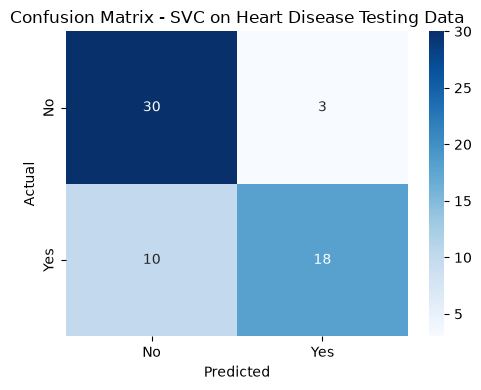

In [17]:
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"],
                            target_names=["No Heart Disease (0)", "Heart Disease (1)"]))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
print(pd.DataFrame(conf_matrix,
      index=["Actual: No", "Actual: Yes"],
      columns=["Predicted: No", "Predicted: Yes"]))

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [18]:
# Demo patient. Change these values to try others.
# To type values yourself, replace the four lines with input() calls, for example:
#   chestpain_input = input("Chest pain (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
chestpain_input = "Asymptomatic"
exerciseangina_input = "Yes"
stslope_input = "Flat"
thal_input = "Reversable Defect"

print(f"ChestPain: {chestpain_input}, ExerciseAngina: {exerciseangina_input}, STSlope: {stslope_input}, Thal: {thal_input}")

ChestPain: Asymptomatic, ExerciseAngina: Yes, STSlope: Flat, Thal: Reversable Defect


#### Step 8.2: Convert User Input into Feature Vector

In [19]:
user_input = pd.DataFrame({
    "ChestPain": [chestpain_input],
    "ExerciseAngina": [exerciseangina_input],
    "STSlope": [stslope_input],
    "Thal": [thal_input]
})
print(user_input)

      ChestPain ExerciseAngina STSlope               Thal
0  Asymptomatic            Yes    Flat  Reversable Defect


#### Step 8.3: Label Encoding of Feature Vector

In [20]:
unseen_data_features = user_input.copy()

unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exerciseangina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["STSlope"] = stslope_label_encoder.transform(user_input["STSlope"])
unseen_data_features["Thal"] = thal_label_encoder.transform(user_input["Thal"])

print(unseen_data_features)

   ChestPain  ExerciseAngina  STSlope  Thal
0          0               1        1     2


#### Step 8.4: Load the Saved Model

In [21]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))

#### Step 8.5: Model Prediction

In [22]:
predicted = model.predict(unseen_data_features)

if predicted == 1:
    prediction = "HEART DISEASE LIKELY"
else:
    prediction = "NO HEART DISEASE LIKELY"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts

I have not collected real feedback from doctors. The table below is a sample of what feedback would look like. I wrote it by checking the model's predictions on a few cases myself.

In [23]:
test_cases = pd.DataFrame({
    "ChestPain": ["Asymptomatic", "Atypical Angina", "Typical Angina"],
    "ExerciseAngina": ["Yes", "No", "No"],
    "STSlope": ["Flat", "Upsloping", "Downsloping"],
    "Thal": ["Reversable Defect", "Normal", "Fixed Defect"],
})
encoded = test_cases.copy()
encoded["ChestPain"] = chestpain_label_encoder.transform(test_cases["ChestPain"])
encoded["ExerciseAngina"] = exerciseangina_label_encoder.transform(test_cases["ExerciseAngina"])
encoded["STSlope"] = stslope_label_encoder.transform(test_cases["STSlope"])
encoded["Thal"] = thal_label_encoder.transform(test_cases["Thal"])
test_cases["Model says"] = ["Heart Disease" if p == 1 else "No Heart Disease" for p in model.predict(encoded)]
print(test_cases.to_string(index=False))

      ChestPain ExerciseAngina     STSlope              Thal       Model says
   Asymptomatic            Yes        Flat Reversable Defect    Heart Disease
Atypical Angina             No   Upsloping            Normal No Heart Disease
 Typical Angina             No Downsloping      Fixed Defect No Heart Disease


#### Step 9.2: List of Potential Improvements

In [24]:
improvements = [
    "Add numeric attributes such as age, cholesterol, resting blood pressure and max heart rate (the assignment limits us to 4 inputs, but a real system should use more)",
    "Use more patients. 301 patients is small, and the Cleveland data comes from one hospital only",
    "Compare other models such as Logistic Regression, Random Forest and Decision Tree",
    "Tune the model to get higher recall, so fewer sick patients are missed",
    "Test the system with doctors before any real use",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Add numeric attributes such as age, cholesterol, resting blood pressure and max heart rate (the assignment limits us to 4 inputs, but a real system should use more)
2. Use more patients. 301 patients is small, and the Cleveland data comes from one hospital only
3. Compare other models such as Logistic Regression, Random Forest and Decision Tree
4. Tune the model to get higher recall, so fewer sick patients are missed
5. Test the system with doctors before any real use


#### Step 9.3: Improve the Model Based on Feedback

In [25]:
print("Next version: add more attributes, compare models, retrain, and check that recall improves before replacing svc_trained_model.pkl")

Next version: add more attributes, compare models, retrain, and check that recall improves before replacing svc_trained_model.pkl


## Step 10: Deploy the Model on the Cloud
I deployed the trained model as a web app with **Streamlit Community Cloud**. Steps:

1. Create a public GitHub repository.
2. Upload `app.py`, `requirements.txt`, `runtime.txt` and `svc_trained_model.pkl`.
3. Go to https://share.streamlit.io and sign in with GitHub.
4. Click **Create app**, pick the repository, branch `main` and main file `app.py`, then click **Deploy**.
5. Copy the live link and paste it at the top of this notebook.

The app recreates the same Label Encoders as this notebook. Because the encoders are fitted on the same fixed category lists, the numbers are identical and predictions match the notebook.

## Conclusion
I built a Heart Disease Prediction System in the same steps as the Titanic system. It uses only 4 inputs: chest pain type, exercise angina, ST slope and thal. The Support Vector Classifier reached **0.79 accuracy** on 61 test patients (301 patients in total after removing 2 rows with missing values).

The model is good at finding healthy patients (recall 0.91) but it misses some sick ones (recall 0.64 for heart disease, 10 of 28 missed). This is the main weakness. For a medical use, recall for the sick class should be higher. Adding more attributes such as age and max heart rate should help.

Patients with asymptomatic chest pain, exercise angina and a reversable thal defect were most often predicted as having heart disease. This matches the patterns seen in the data. The model is a learning project and must not be used for real diagnosis.